In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Real-Time Malicious URL Detection System Using Machine Learning Techniques
**Student:** Abdullahi Umar Umar (`*2024/CP/CYB/0209*`)  
**Supervisor:** Mr. M.A. Shehu | **Department:** Cyber Security, Federal University of Lafia  

## 1. Environment Setup & Dataset Ingestion
****In this section, we load the Kaggle Malicious URLs dataset (`/kaggle/input/datasets/sid321axn/malicious-urls-dataset`), inspect its structure, remove duplicate or malformed URLs, and prepare binary labels (`0 = Benign`, `1 = Malicious`).****

# Code Cell: Install Libraries & Load Data

In [6]:
import os
import re
import math
import time
import joblib
import warnings
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

csv_file = "/kaggle/input/datasets/sid321axn/malicious-urls-dataset/malicious_phish.csv"
df_raw = pd.read_csv(csv_file)
print(f"Raw Dataset Shape: {df_raw.shape}")
df_raw.head()

Raw Dataset Shape: (651191, 2)


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement



# 2. Data Cleaning & Exploratory Data Analysis (EDA)
****We audit missing values, remove duplicate URLs, inspect the multi-class threat breakdown (`benign`, `phishing`, `defacement`, `malware`), and analyze URL length distributions across classes.****

# **Code Cell: Cleaning & EDA Plots**

Missing values before cleaning:
 url     0
type    0
dtype: int64

Cleaned Dataset Shape: (641115, 4)

Original Category Counts:
 type
benign        428080
defacement     95308
phishing       94082
malware        23645
Name: count, dtype: int64

Binary Label Distribution:
 label
0    428080
1    213035
Name: count, dtype: int64


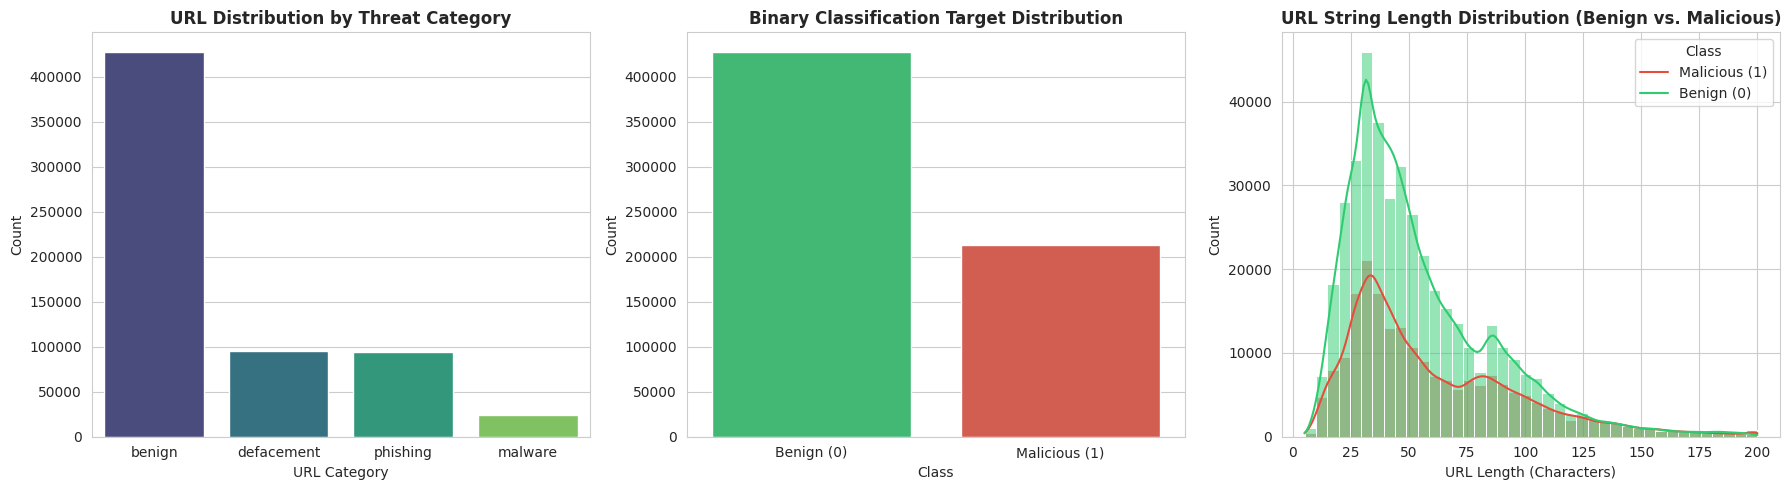

In [7]:
# 1. Clean missing values and duplicates
print("Missing values before cleaning:\n", df_raw.isnull().sum())
df = df_raw.dropna(subset=["url", "type"]).copy()
df["url"] = df["url"].astype(str).str.strip()
df = df[df["url"].str.len() > 4]
df.drop_duplicates(subset=["url"], keep="first", inplace=True)

# 2. Binary target: 0 = Benign, 1 = Malicious (phishing, defacement, malware)
df["label"] = df["type"].apply(lambda x: 0 if str(x).strip().lower() == "benign" else 1)
df["url_len_raw"] = df["url"].str.len()

print(f"\nCleaned Dataset Shape: {df.shape}")
print("\nOriginal Category Counts:\n", df["type"].value_counts())
print("\nBinary Label Distribution:\n", df["label"].value_counts())

# 3. EDA Plots (Saved at 300 DPI for Chapter 4 of your report)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x="type", order=df["type"].value_counts().index, palette="viridis", ax=axes[0])
axes[0].set_title("URL Distribution by Threat Category", fontweight="bold")
axes[0].set_xlabel("URL Category")
axes[0].set_ylabel("Count")

sns.countplot(data=df, x="label", palette=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_xticklabels(["Benign (0)", "Malicious (1)"])
axes[1].set_title("Binary Classification Target Distribution", fontweight="bold")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")

sns.histplot(
    data=df[df["url_len_raw"] <= 200], x="url_len_raw", hue="label",
    bins=40, kde=True, palette=["#2ecc71", "#e74c3c"], ax=axes[2]
)
axes[2].set_title("URL String Length Distribution (Benign vs. Malicious)", fontweight="bold")
axes[2].set_xlabel("URL Length (Characters)")
axes[2].legend(title="Class", labels=["Malicious (1)", "Benign (0)"])

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=300)
plt.show()

# 3. Multi-Dimensional URL Feature Engineering
**We sample a balanced benchmark dataset of **120,000 URLs** (60,000 Benign and 60,000 Malicious) and extract **26 lexical, structural, obfuscation, and phishing-keyword features**.**

**Code Cell: Offline Feature Extraction & Correlation Plot**

Extracting 26 features from 120,000 balanced URLs...
Feature extraction complete! Shape: (120000, 26)


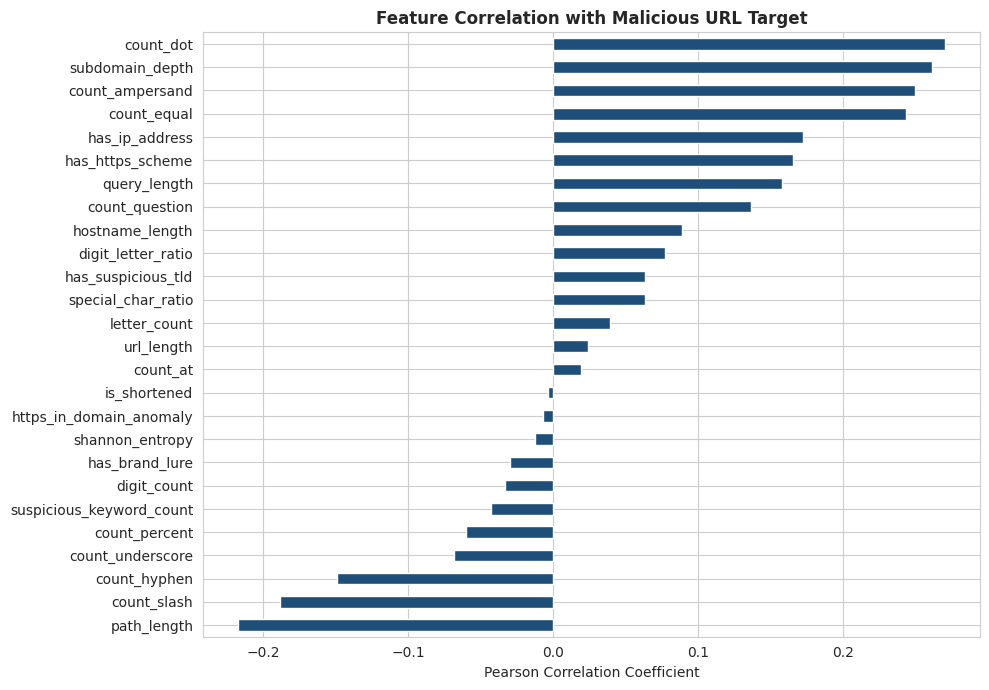

In [9]:
SHORTENERS = {
    "bit.ly", "tinyurl.com", "goo.gl", "t.co", "ow.ly", "is.gd", "buff.ly",
    "adf.ly", "bit.do", "mcaf.ee", "su.pr", "tiny.cc", "lnkd.in", "cutt.ly", "rb.gy"
}
SUSPICIOUS_KEYWORDS = [
    "login", "signin", "verify", "secure", "account", "update", "banking",
    "confirm", "paypal", "ebay", "webscr", "password", "credential", "wallet",
    "recover", "unlock", "billing", "invoice", "support", "service", "alert",
    "suspend", "limited", "auth", "token", "free", "bonus", "prize", "win"
]
SUSPICIOUS_TLDS = {
    "tk", "ml", "ga", "cf", "gq", "xyz", "top", "club", "work", "click",
    "link", "cam", "icu", "vip", "win", "bid", "stream", "download", "zip"
}

FEATURE_COLUMNS = [
    "url_length", "hostname_length", "path_length", "query_length",
    "shannon_entropy", "digit_count", "letter_count", "digit_letter_ratio",
    "special_char_ratio", "count_dot", "count_hyphen", "count_underscore",
    "count_slash", "count_question", "count_equal", "count_at",
    "count_percent", "count_ampersand", "has_ip_address", "is_shortened",
    "subdomain_depth", "has_https_scheme", "https_in_domain_anomaly",
    "has_suspicious_tld", "suspicious_keyword_count", "has_brand_lure"
]

def calc_entropy(text: str) -> float:
    if not text:
        return 0.0
    counts = Counter(text)
    length = len(text)
    return -sum((c / length) * math.log2(c / length) for c in counts.values())

def parse_domain_parts(hostname: str):
    parts = [p for p in hostname.split(".") if p]
    if len(parts) >= 2:
        tld = parts[-1]
        domain = parts[-2]
        subdomains = parts[:-2]
        reg_domain = f"{domain}.{tld}"
    elif len(parts) == 1:
        tld, domain, subdomains, reg_domain = "", parts[0], [], parts[0]
    else:
        tld, domain, subdomains, reg_domain = "", "", [], ""
    return reg_domain, domain, tld, subdomains

def extract_features(raw_url: str) -> list:
    url = str(raw_url).strip()
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url):
        url = "http://" + url

    # Safe URL parsing to handle malformed brackets/IPv6 strings in raw dataset
    try:
        parsed = urlparse(url)
        hostname = (parsed.hostname or "").lower()
        path = parsed.path or ""
        query = parsed.query or ""
        scheme = parsed.scheme.lower()
    except ValueError:
        clean_url = url.replace("[", "").replace("]", "")
        parsed = urlparse(clean_url)
        hostname = (parsed.hostname or "").lower()
        path = parsed.path or ""
        query = parsed.query or ""
        scheme = parsed.scheme.lower()

    reg_domain, domain, tld, subdomains = parse_domain_parts(hostname)

    url_len = len(url)
    digits = sum(c.isdigit() for c in url)
    letters = sum(c.isalpha() for c in url)
    specials = sum(not c.isalnum() for c in url)

    is_ip = 1 if (re.match(r"^(?:\d{1,3}\.){3}\d{1,3}$", hostname) or ":" in hostname) else 0
    is_short = 1 if reg_domain in SHORTENERS else 0
    is_https = 1 if scheme == "https" else 0
    https_anomaly = 1 if ("https" in hostname or "http" in hostname) else 0
    bad_tld = 1 if tld in SUSPICIOUS_TLDS else 0

    lower_url = url.lower()
    kw_count = sum(1 for kw in SUSPICIOUS_KEYWORDS if kw in lower_url)
    brands = ["paypal", "apple", "microsoft", "google", "amazon", "netflix", "bank", "gtbank", "zenith"]
    has_brand = 1 if any(b in lower_url and b != domain for b in brands) else 0

    return [
        url_len, len(hostname), len(path), len(query),
        round(calc_entropy(url), 4), digits, letters,
        round(digits / max(letters, 1), 4), round(specials / max(url_len, 1), 4),
        url.count("."), url.count("-"), url.count("_"), url.count("/"),
        url.count("?"), url.count("="), url.count("@"), url.count("%"), url.count("&"),
        is_ip, is_short, len(subdomains), is_https, https_anomaly,
        bad_tld, kw_count, has_brand
    ]

# Balance dataset to 120,000 records (60,000 Benign + 60,000 Malicious)
n_per_class = min(60000, (df["label"] == 0).sum(), (df["label"] == 1).sum())
df_bal = pd.concat([
    df[df["label"] == 0].sample(n=n_per_class, random_state=42),
    df[df["label"] == 1].sample(n=n_per_class, random_state=42)
]).sample(frac=1.0, random_state=42).reset_index(drop=True)

print(f"Extracting 26 features from {len(df_bal):,} balanced URLs...")
X = pd.DataFrame([extract_features(u) for u in df_bal["url"]], columns=FEATURE_COLUMNS)
y = df_bal["label"]
print("Feature extraction complete! Shape:", X.shape)

plt.figure(figsize=(10, 7))
corr_with_target = X.assign(label=y).corr()["label"].drop("label").sort_values()
corr_with_target.plot(kind="barh", color="#1f4e78")
plt.title("Feature Correlation with Malicious URL Target", fontweight="bold")
plt.xlabel("Pearson Correlation Coefficient")
plt.tight_layout()
plt.savefig("feature_correlation.png", dpi=300)
plt.show()

# 4. Model Training, Benchmarking & Evaluation
****We partition the dataset using a **70% Training / 15% Validation / 15% Hold-Out Test** stratified split and benchmark **Random Forest**, **XGBoost**, **LightGBM**, and **Support Vector Machine (SVM)** against our targets (**≥ 95% Accuracy**, **≥ 0.94 F1-Score**, and **< 200 ms per-URL inference latency**).****

**Code Cell: Train, Benchmark, Plot & Export Model**

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score,ROC-AUC,Latency (ms/URL),Train Time (s)
0,Random Forest,89.96,90.04,89.86,0.8995,0.9660,0.0678,8.20
1,XGBoost,89.73,89.52,90.00,0.8976,0.9644,0.0076,1.84
2,LightGBM,89.45,89.26,89.69,0.8948,0.9632,0.0070,1.77
3,Support Vector Machine (SVM),77.52,79.93,73.48,0.7657,0.8382,0.0116,8.38


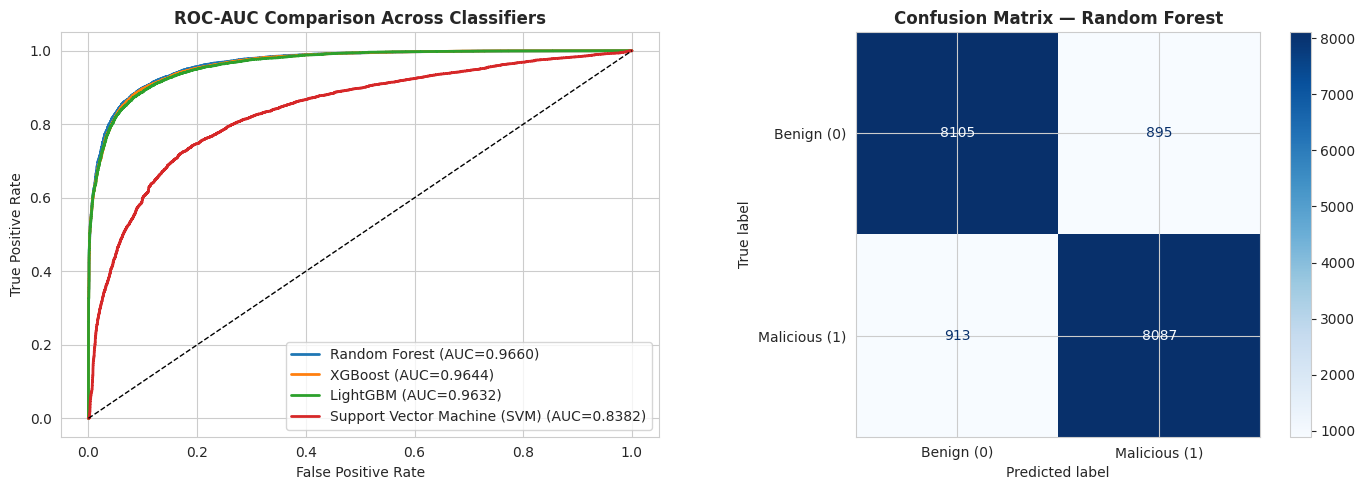


[✓] Exported winning model (Random Forest) to 'malicious_url_model.joblib'


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=24, min_samples_split=4, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.85, colsample_bytree=0.85, eval_metric="logloss", n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, num_leaves=63, learning_rate=0.1, subsample=0.85, colsample_bytree=0.85, n_jobs=-1, random_state=42, verbose=-1),
    "Support Vector Machine (SVM)": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=3000, random_state=42)))
    ])
}

results = []
roc_curves = {}
trained = {}

for name, clf in models.items():
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    train_time = time.perf_counter() - t0

    sample_batch = X_test.iloc[:1000]
    t_inf = time.perf_counter()
    _ = clf.predict_proba(sample_batch)
    latency_ms = ((time.perf_counter() - t_inf) / len(sample_batch)) * 1000

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4),
        "Latency (ms/URL)": round(latency_ms, 4),
        "Train Time (s)": round(train_time, 2)
    })
    roc_curves[name] = (*roc_curve(y_test, y_prob)[:2], auc)
    trained[name] = clf

benchmark_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
display(benchmark_df)
benchmark_df.to_csv("benchmark_results.csv", index=False)

best_name = benchmark_df.iloc[0]["Model"]
best_model = trained[best_name]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (fpr, tpr, auc) in roc_curves.items():
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC-AUC Comparison Across Classifiers", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

cm = confusion_matrix(y_test, best_model.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Benign (0)", "Malicious (1)"]).plot(ax=axes[1], cmap="Blues")
axes[1].set_title(f"Confusion Matrix — {best_name}", fontweight="bold")

plt.tight_layout()
plt.savefig("evaluation_plots.png", dpi=300)
plt.show()

joblib.dump({
    "model_name": best_model_name if "best_model_name" in locals() else best_name,
    "model": best_model,
    "feature_columns": FEATURE_COLUMNS,
    "benchmark": benchmark_df.to_dict(orient="records")
}, "malicious_url_model.joblib")

print(f"\n[✓] Exported winning model ({best_name}) to 'malicious_url_model.joblib'")